# 02 · Text models: which sentiment model works best?

**Goal:** compare all sentiment models on the same test set and explain what they learned.

**Models:**
- *Ours, trained locally:* TextBlob (rules, course baseline), CountVectorizer + Naive Bayes, TF-IDF + Logistic Regression, MiniLM embeddings + Logistic Regression.
- *Ready-made from the internet, used as they are:* Cardiff RoBERTa (3 classes, trained on tweets), nlptown BERT (1–5 stars), the default Hugging Face `pipeline` model (positive/negative only).
- *Fine-tuned on our data (Colab GPU):* DistilBERT, and the Cardiff RoBERTa improved on our reviews.

**Inputs:** `data/processed/`, `results/metrics.json` (written by `scripts/train_text_models.py` and the Colab notebook).
**Outputs:** comparison figures in `results/figures/`.

Main metric: **macro-F1** (average of the three class F1 scores, so neutral counts as much as the others).
Every model picked its settings on the validation set; the test set was used once, at the end.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. Comparison table

In [2]:
from src.evaluate import comparison_table, import_colab_metrics
print("Imported from Colab:", import_colab_metrics() or "nothing yet")
table = comparison_table("text")
table

Imported from Colab: nothing yet


,type,test macro-F1,test accuracy,F1 negative,F1 neutral,F1 positive,external F1 (pos/neg),ms / review,size MB
model,,,,,,,,,
tfidf_logreg,TF-IDF (1-2 grams) + Logistic Regression,0.7309,0.7312,0.7443,0.6276,0.8208,0.8792,0.01,3.2
naive_bayes,CountVectorizer + MultinomialNB,0.7244,0.7234,0.7181,0.6324,0.8229,0.9061,0.01,4.0
bench_nlptown_stars,ready-made (no training),0.7151,0.7402,0.7724,0.5135,0.8595,1.0000,125.09,669.4
minilm_logreg,MiniLM embeddings + Logistic Regression,0.6956,0.6968,0.7165,0.5789,0.7915,0.9865,3.03,90.9
bench_cardiffnlp_roberta,ready-made (no training),0.6092,0.6550,0.7123,0.3086,0.8069,1.0000,150.91,498.6
textblob,rule-based baseline,0.5896,0.5913,0.6480,0.4461,0.6746,0.9593,0.09,NaN
bench_hf_default_pipeline,ready-made (no training),0.4802,0.5955,0.6725,0.0000,0.7681,0.9865,93.72,267.8


In [3]:
from src.evaluate import plot_model_comparison
plot_model_comparison(table, "test macro-F1");

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


**External test (Customer Feedback, 75 short reviews, positive vs negative only).** These are short, very
clear sentences, mostly not about products. It checks whether a model still works on unfamiliar text.

In [4]:
plot_model_comparison(table, "external F1 (pos/neg)", filename="text_model_comparison_external");

## 2. Results per source (test set macro-F1)

In [5]:
from src.evaluate import load_metrics
per_source = pd.DataFrame({name: {src: v["macro_f1"] for src, v in m["test_per_source"].items()}
                           for name, m in load_metrics()["text"].items()}).T
per_source.loc[table.index]

,amazon2023_electronics,amazon2023_grocery,amazon_lecturer,flipkart
model,,,,
tfidf_logreg,0.7189,0.7422,0.7291,0.7284
naive_bayes,0.7207,0.7361,0.5961,0.7165
bench_nlptown_stars,0.7233,0.7154,0.7152,0.7048
minilm_logreg,0.6726,0.7082,0.6906,0.7030
bench_cardiffnlp_roberta,0.6086,0.5841,0.5636,0.6315
textblob,0.5681,0.5914,0.5250,0.6034
bench_hf_default_pipeline,0.4788,0.4860,0.5130,0.4746


## 3. Confusion matrices: where do the models get confused?

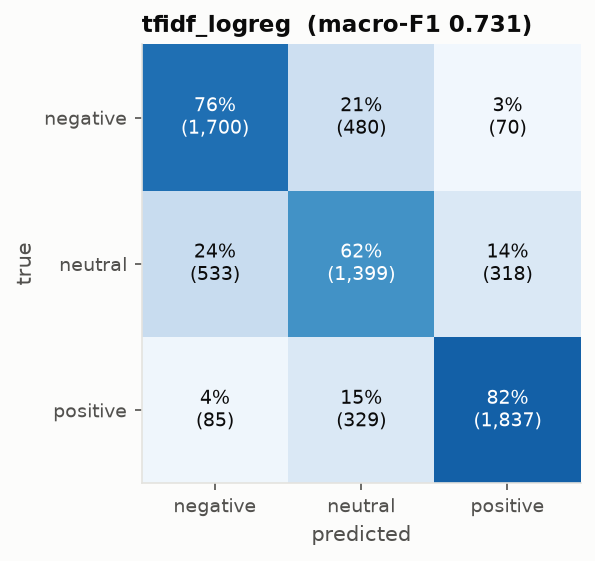

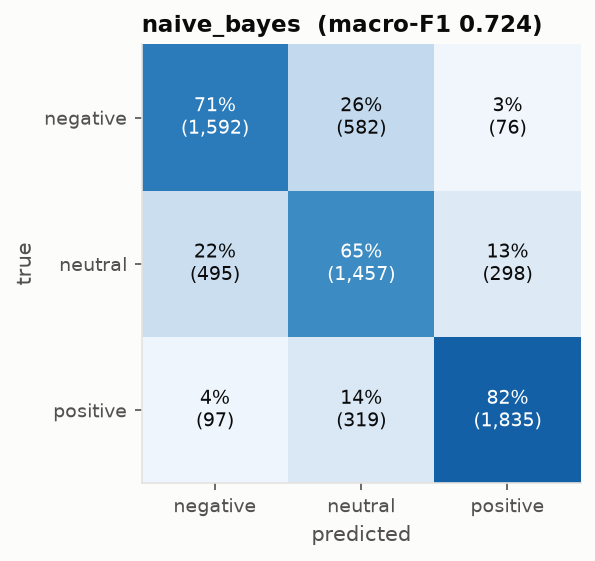

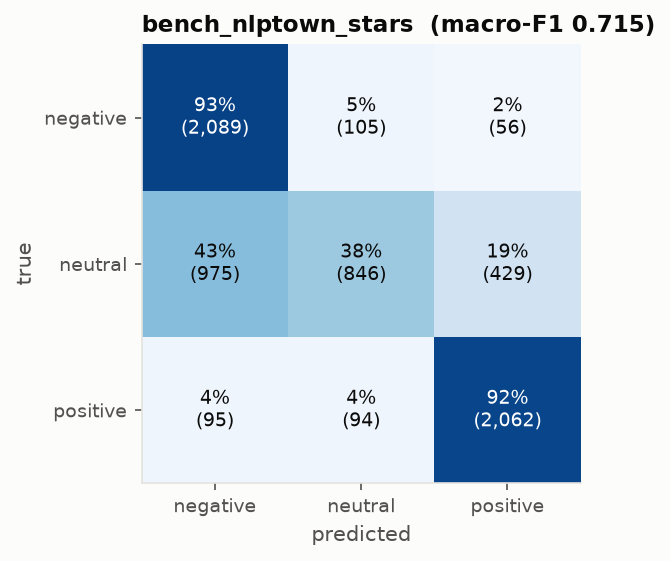

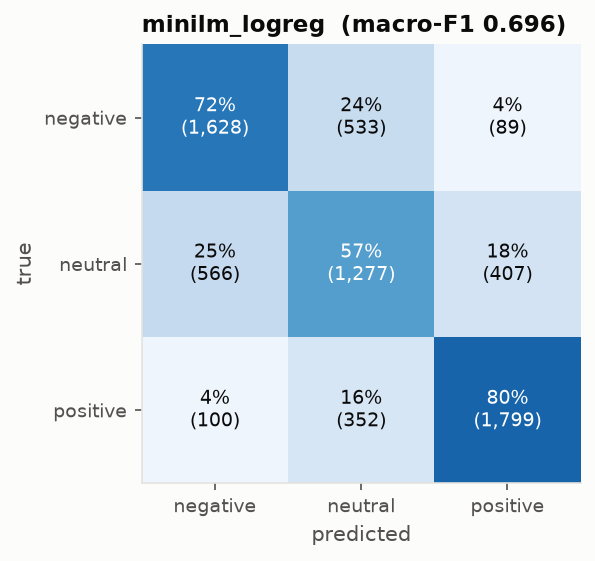

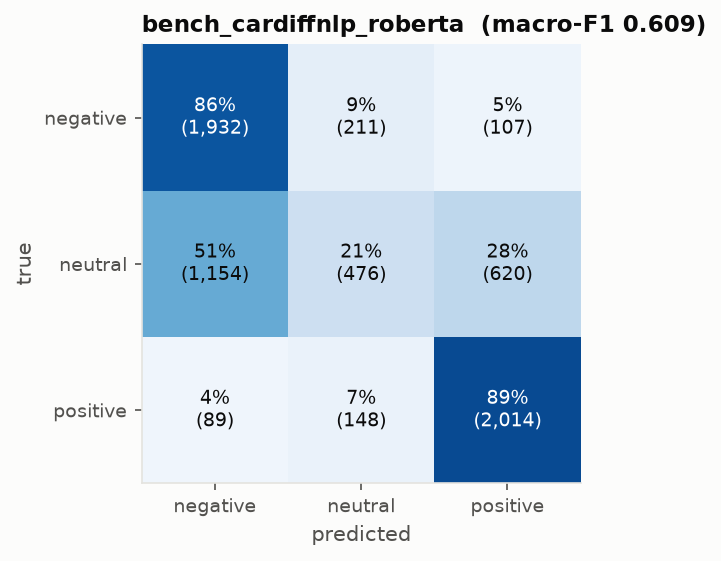

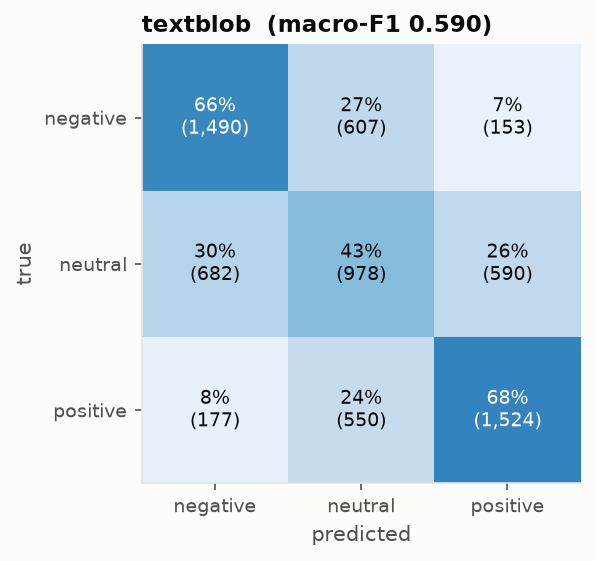

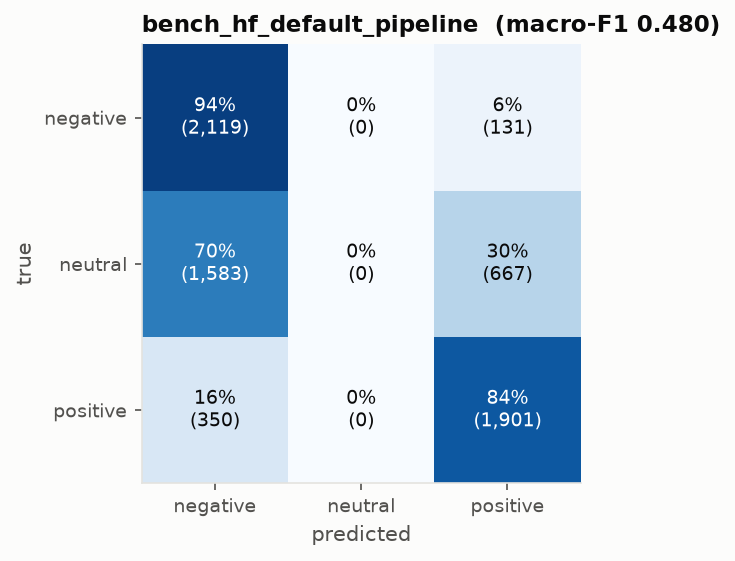

In [6]:
from pathlib import Path
figs = Path("../results/figures")
for name in table.index:
    f = figs / f"cm_text_{name}.png"
    if f.exists():
        display(Image(filename=str(f), width=330))

## 4. Explainability: what does TF-IDF + Logistic Regression look for?

Logistic Regression gives every word (and word pair) a weight per class. The biggest weights are
the words that push a review towards that class. Word pairs like "not worth" or "stopped working"
are the reason we used 1–2 grams.

In [7]:
import joblib
from src.config import path
from src.text_models import TfidfLogRegModel
from src.evaluate import plot_top_words
tfidf = TfidfLogRegModel()
tfidf.pipe = joblib.load(path("models_train") / "text_tfidf_logreg.joblib")
plot_top_words(tfidf.top_words(15));

## 5. Error analysis: the most confident mistakes

Reviews where TF-IDF + LR was *sure* and still wrong. These show the limits of a word-counting model and of star-based labels.

In [8]:
from src.evaluate import misclassified_examples
test = pd.read_csv("../data/processed/text_test.csv")
misclassified_examples(test, "tfidf_logreg", n=10)

,source,rating,label,pred,confidence,text
0,flipkart,3.0,neutral,positive,0.9989,pent are perfect
1,flipkart,3.0,neutral,negative,0.9896,coler is very bad
2,flipkart,3.0,neutral,negative,0.9896,very bad by milton
3,amazon2023_electronics,3.0,neutral,positive,0.9895,Storage. Great value
4,flipkart,3.0,neutral,positive,0.9768,it was awesome thanks to flipkart
5,flipkart,1.0,negative,neutral,0.9695,ok product not so bad
6,flipkart,3.0,neutral,negative,0.9693,this shooes quiliy is bad
7,amazon2023_electronics,4.0,positive,neutral,0.9691,Is it ok. Picture not very good but it does work
8,amazon2023_grocery,3.0,neutral,negative,0.9661,Waste of Money. Basically tastes like warm water
9,flipkart,3.0,neutral,positive,0.9653,wonderful and sturdy gloves awesome delivery by flipkart


## 6. Issue tagger: *what* went wrong

Sentiment says how unhappy a customer is; the tagger (`src/issue_tags.py`) finds concrete problems
and shows the exact phrase that triggered each tag. It handles negation ("the box was **not** damaged" → no tag).

In [9]:
from src.issue_tags import tag_issues
examples = [
    "The box arrived crushed and the jar inside leaked everywhere. I want a refund.",
    "Wrong size, not what I ordered. Returned it.",
    "Stopped working after a week, and the replacement never arrived.",
    "The bread was moldy and past its best before date.",
    "Box was not damaged at all, great packaging, fast delivery!",
]
pd.DataFrame({"review": examples, "tags found (phrase)": [tag_issues(e) for e in examples]})

,review,tags found (phrase)
0,The box arrived crushed and the jar inside leaked everywhere. I want a refund.,"{'damaged_packaging': 'box arrived crushed', 'refund_request': 'refund'}"
1,"Wrong size, not what I ordered. Returned it.","{'wrong_item': 'wrong size', 'refund_request': 'returned'}"
2,"Stopped working after a week, and the replacement never arrived.","{'missing_item': 'never arrived', 'defective_product': 'stopped working'}"
3,The bread was moldy and past its best before date.,{'spoiled_food': 'past its best before'}
4,"Box was not damaged at all, great packaging, fast delivery!",{}


There are no ground-truth tags, so as a sanity check we look at how often each tag fires per sentiment class.
A good tagger fires far more on negative reviews than on positive ones.

In [10]:
from src.issue_tags import tag_rates
(tag_rates(test) * 100).round(1).rename(columns=lambda c: c + " %")

,negative %,neutral %,positive %
damaged_packaging,1.3,0.5,0.0
wrong_item,0.3,0.3,0.0
missing_item,1.4,0.8,0.2
defective_product,12.7,4.0,1.1
spoiled_food,3.6,1.2,0.2
late_delivery,0.4,0.2,0.0
refund_request,11.0,3.8,0.5
any tag,26.8,9.7,1.8


## Key findings

*(Fine-tuned DistilBERT/RoBERTa rows appear in the table once the Colab results are imported; this
section is updated then.)*

- **Simple beats big on our data:** TF-IDF + Logistic Regression (macro-F1 **0.731**) and Naive Bayes (0.724) beat every
  ready-made internet model, including a 670 MB BERT (nlptown, 0.715), while being ~10,000× faster (0.01 vs 125 ms per review) and 200× smaller.
- **Ready-made models struggle with "neutral":** the Cardiff RoBERTa reaches F1 0.31 on neutral, and the default HF pipeline
  can't predict neutral at all (macro-F1 0.48). What counts as "neutral" depends on the data, so models trained on someone else's data don't know our definition.
- **But ready-made models are strong on clear, unfamiliar text:** on the external Customer Feedback set, both RoBERTa and nlptown score 1.00 and MiniLM 0.99,
  while TF-IDF drops to 0.88: word counts only know the vocabulary of our training data.
- **Neutral is the hardest class for every model** (TF-IDF: 62% recall). Negative and positive are almost never swapped (3–4%); the mistakes are mostly "neighbouring" classes.
- **Many "confident mistakes" are label noise**: "pent are perfect" or "very bad" rated 3 stars. Star ratings are a cheap but imperfect label, which caps every model's score.
- **Explainability:** TF-IDF + LR looks for sensible words; the negation phrases we kept on purpose ("not good", "not worth", "not work") are among the strongest negative signals, and hedging words ("but", "ok", "however", "though") drive neutral.
- **Issue tagger:** 27% of negative reviews get at least one tag vs 1.8% of positive ones; refunds/returns and defective products are the most common problems.